# O IMPACTO DAS COMPETÊNCIAS DA REDAÇÃO NA NOTA FINAL

## Hipótese

Essa análise parte da ideia de que os alunos têm diferentes desempenhos nas 5 competências avaliadas na redação. O objetivo é entender qual a distribuição de notas entre essas competências. Dessa forma, pode-se encontrar os pontos fortes dos alunos e também os pontos que necessitam de mais atenção.

## Metodologia e engenharia

Para obter a análise desejada, criamos uma tabela mart contendo apenas o conteúdo necessário. Para isso, cruzamos as notas da tabela de respostas com uma tabela construída por nós que contém a descrição das competências. Essa tabela de competências foi baseada no manual de redação, fornecido pelo INEP junto com os microdados. A tabela de competências foi criada manualmente, pois tem apenas 5 linhas e seu conteúdo não mudou desde a criação em 2012.

Essa tabela contém apenas as 5 competências da redação e suas respectivas médias ao longo dos anos analisados e já está pronta para visualização.

## Importação dos dados

In [19]:
import duckdb
import pandas as pd


# abrir a conexão com banco de dados
con = duckdb.connect('../database/enem.duckdb')

# criar a consulta em SQL
query = """
    SELECT * FROM mart_redacao
"""
# consultar a tabela e salvar em um dataframe
df = con.execute(query).df()

# criar uma lista com nomes reduzidos das competências. Esses nomes serão utlizados como rótulos do gráfico para evitar poluição visual.
rotulos = [
    "Domínio da escrita formal",
    "Compreensão da proposta",
    "Organização dos argumentos",
    "Coesão e mecanismos lógicos",
    "Proposta de intervenção"
]

#adicionar a nova coluna de rótulos no dataframe
df['rotulos'] = rotulos

# ordenar o dataset em ordem decrescente de média de notas
df=df.sort_values (by='nota_media', ascending=False)

# visualizar parte do dataframe
df.head()

,id,descricao,nota_media,rotulos
1,2,Compreender a proposta de redação e aplicar co...,145.15,Compreensão da proposta
3,4,Demonstrar conhecimento dos mecanismos linguís...,133.40,Coesão e mecanismos lógicos
0,1,Demonstrar domínio da modalidade escrita forma...,124.53,Domínio da escrita formal
2,3,"Selecionar, relacionar, organizar e interpreta...",121.75,Organização dos argumentos
4,5,Elaborar proposta de intervenção para o proble...,116.72,Proposta de intervenção


## Estratégia de visualização

Para melhor visualização do resultado, foi criado um gráfico de barras horizontais. Esse gráfico relaciona exatamente cada competência com sua média de notas obtidas ao longo do período analisado. O tamanho de cada barra e a ordenação decrescente fornecem noção visual instantânea de qual competência tem maior ou menor nota média.

## Visualização

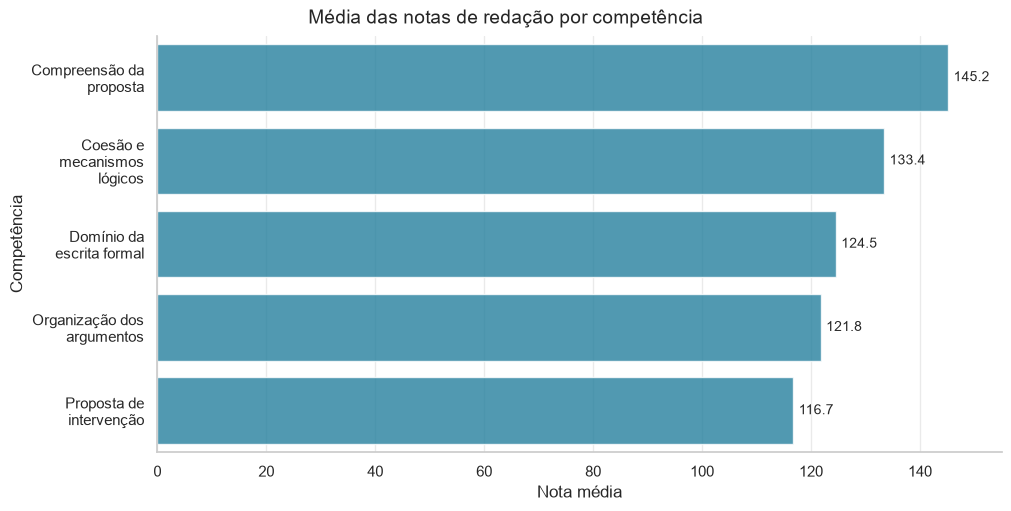

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt
import textwrap

# aplicar o textwrap para quebrar automaticamente o texto do nome das competências. Fica melhor de visualizar no gráfico.
df['rotulos'] = df['rotulos'].apply(lambda x: textwrap.fill(x, width=15))

# cria a moldura (fig) e o eixo do gráfico (ax)
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained') # layout para considerar as bordas da figura ao alinhar o título
# Configurando o estilo do Seaborn
sns.set_theme(style="whitegrid")

# Plotando o gráfico de barras
ax = sns.barplot(
    data=df, 
    x="nota_media", 
    y="rotulos", 
    alpha=0.8,
    color="#118AB2",
    ax=ax # especificar qual eixo deve ir esse gráfico (nesse caso só tem 1)
)

# inserir rótulos de dados
ax.bar_label(
    ax.containers[0], # colocar rótulos nas barras
    fmt='%.1f', # formatação do número com 1 casa decimal
    padding=4, # ajuste de posicionamento
    fontsize=10
)

# Adicionando titulo e rótulos
fig.suptitle("Média das notas de redação por competência", fontsize=14)
plt.xlabel("Nota média", fontsize=12)
plt.ylabel("Competência", fontsize=12)

# ajustar o limite direito do eixo X para dar espaço ao rótulo de dados
ax.set_xlim(left=0, right=155)

# controlar a transparência das barras verticais do grid
ax.grid(axis='x', alpha=0.4)

# remover as linhas superior e direita da caixa do gráfico.
sns.despine()

# Exportando o artefato final em alta resolução
plt.savefig('../graficos/competencias_redacao.png', dpi=300)

plt.show()

## Conclusões

Nota-se pelas médias apresentadas que existe uma diferença considerável entre as médias de cada competência. A diferença entre a maior e a menor média é de aproximadamente 24%.

O maior desempenho em compreensão da proposta indica que os alunos entendem o que devem fazer e sobre o que devem escrever. Essa compreensão é reforçada pelos textos de apoio que acompanham cada proposta. Porém as notas mais baixas em organização dos argumentos representa que, na hora da prática, o aluno ainda tem dificuldades. Esse fato traz a necessidade de mais debates e discussões na preparação dos estudantes, visando melhorar a capacidade de argumentação e organização das ideias.

A segunda maior nota é no quesito coesão. Isso indica que o aluno é bem treinado na estrutura básica esperada para a redação, sabendo utilizar conectivos para ligar os parágrafos e as ideias. Naturalmente que uma melhora nesse quesito passa diretamente pela prática de mais redações ao longo da preparação, conferindo assim prática de encadeamento de texto. Tal prática pode também ajudar na melhora do domínio da escrita formal a medida que o estudante aprende com seus erros gramaticais.

O claro destaque negativo é a proposta de intervenção que respeite os direitos humanos.